# Notebook 02: Structured Exploratory Data Analysis (EDA)
**Project**: Duka Electronics Retail & E-Commerce Performance (H1 2026)  
**Track**: Track A - Retail and E-commerce Performance  
**Author**: George Tipango  
**Date**: November 2026  
**License**: CC BY 4.0 (KDPA 2019 Compliant)

---

## Objectives & Analytical Blueprint
This notebook conducts a structured, hypothesis-driven Exploratory Data Analysis (EDA) of Duka Electronics' sales performance for H1 2026 (January 1 – June 30, 2026).

We structure our exploration into three analytical tiers:
1. **Univariate Analysis**: Evaluating distributions, central tendencies, spreads, and outliers across numerical variables (`order_total_kes`, `order_profit_kes`, `discount_pct`, `quantity`) and categorical frequencies (`payment_method`, `channel`, `category`).
2. **Bivariate & Time-Series Analysis**: Evaluating interaction dynamics—revenue and profitability across regional branches, product category volume vs revenue Pareto relationships, promotional discount margin erosion, and weekly revenue velocity.
3. **Customer Segmentation Analysis (RFM)**: Building a behavioral RFM (Recency, Frequency, Monetary) segmentation model to identify high-value Champions, core Loyalists, and At-Risk customer cohorts.


In [1]:
import os
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Professional aesthetic styling aligned with Week 6 data visualization principles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.dpi'] = 120

# Create figures directory if not exists
os.makedirs('../reports/figures', exist_ok=True)

# Connect to clean SQLite database
conn = sqlite3.connect('../database/duka_sales.db')

# Ingest dataframes
df_stores = pd.read_sql("SELECT * FROM dim_stores", conn)
df_products = pd.read_sql("SELECT * FROM dim_products", conn)
df_customers = pd.read_sql("SELECT * FROM dim_customers", conn)
df_orders = pd.read_sql("SELECT * FROM fct_orders", conn)
df_order_items = pd.read_sql("SELECT * FROM fct_order_items", conn)

conn.close()

# Prepare master analytical dataset for completed orders
df_orders_clean = df_orders[df_orders['order_status'] == 'Completed'].copy()
df_orders_clean['order_date'] = pd.to_datetime(df_orders_clean['order_date'])
df_orders_clean['month_year'] = df_orders_clean['order_date'].dt.to_period('M')
df_orders_clean['quarter'] = 'Q' + df_orders_clean['order_date'].dt.quarter.astype(str) + '-2026'

print(f"Loaded {len(df_orders_clean):,} completed orders totaling KES {df_orders_clean['order_total_kes'].sum():,.2f}")


Loaded 8,934 completed orders totaling KES 1,007,753,255.00


## 1. Univariate Analysis: Numerical Metrics
We examine the distribution of key financial metrics: Order Total, Order Profit, and Promotional Discounts.


In [2]:
num_cols = ['order_total_kes', 'order_profit_kes', 'discount_pct', 'items_count']
stats_df = df_orders_clean[num_cols].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]).T
stats_df['IQR'] = stats_df['75%'] - stats_df['25%']
stats_df['skewness'] = df_orders_clean[num_cols].skew()
stats_df[['mean', 'std', '5%', '25%', '50%', '75%', '95%', 'IQR', 'skewness']]


,mean,std,5%,25%,50%,75%,95%,IQR,skewness
order_total_kes,112799.782292,95230.561678,12150.0,36450.0,85000.0,164675.00,304000.00,128225.00,1.311653
order_profit_kes,20305.748265,17852.138817,1700.0,7000.0,14500.0,30000.00,57000.00,23000.00,1.496371
discount_pct,0.033591,0.053663,0.0,0.0,0.0,0.05,0.15,0.05,1.557147
items_count,1.888628,1.137978,1.0,1.0,1.0,2.00,4.00,1.00,1.375118


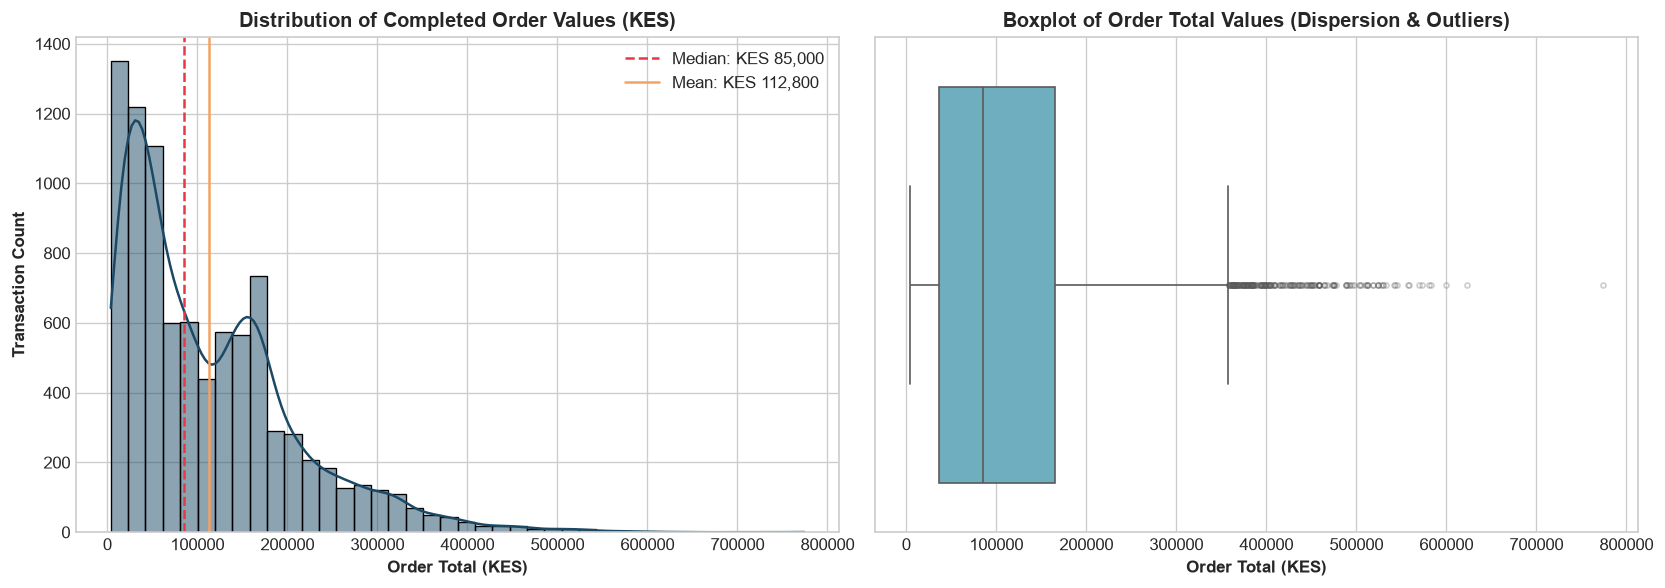

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Order Total Distribution
sns.histplot(df_orders_clean['order_total_kes'], bins=40, kde=True, ax=axes[0], color='#1b4965')
axes[0].set_title('Distribution of Completed Order Values (KES)')
axes[0].set_xlabel('Order Total (KES)')
axes[0].set_ylabel('Transaction Count')
axes[0].axvline(df_orders_clean['order_total_kes'].median(), color='#e63946', linestyle='--', label=f"Median: KES {df_orders_clean['order_total_kes'].median():,.0f}")
axes[0].axvline(df_orders_clean['order_total_kes'].mean(), color='#f4a261', linestyle='-', label=f"Mean: KES {df_orders_clean['order_total_kes'].mean():,.0f}")
axes[0].legend()

# Plot 2: Boxplot showing dispersion and high-value orders
sns.boxplot(x=df_orders_clean['order_total_kes'], ax=axes[1], color='#62b6cb', flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3})
axes[1].set_title('Boxplot of Order Total Values (Dispersion & Outliers)')
axes[1].set_xlabel('Order Total (KES)')

plt.tight_layout()
plt.savefig('../reports/figures/02_univariate_order_totals.png')
plt.show()


## 2. Univariate Analysis: Categorical Distributions
We assess the distribution of transactions across payment rails and store channels.


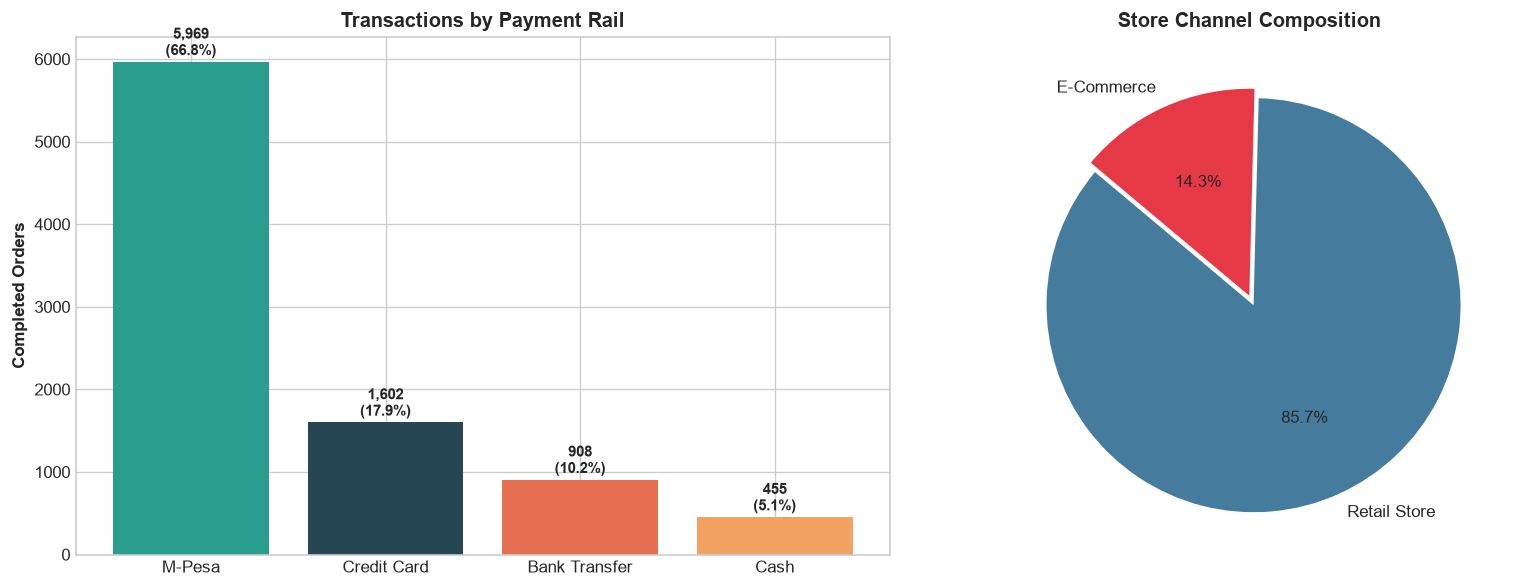

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Payment Method Distribution
pm_counts = df_orders_clean['payment_method'].value_counts()
colors = ['#2a9d8f', '#264653', '#e76f51', '#f4a261']
axes[0].bar(pm_counts.index, pm_counts.values, color=colors)
axes[0].set_title('Transactions by Payment Rail')
axes[0].set_ylabel('Completed Orders')
for i, v in enumerate(pm_counts.values):
    pct = (v / len(df_orders_clean)) * 100
    axes[0].text(i, v + 80, f"{v:,}\n({pct:.1f}%)", ha='center', fontsize=9, fontweight='bold')

# Channel Distribution
channel_counts = df_stores['channel'].value_counts()
axes[1].pie(channel_counts.values, labels=channel_counts.index, autopct='%1.1f%%', startangle=140, colors=['#457b9d', '#e63946'], explode=[0.05, 0])
axes[1].set_title('Store Channel Composition')

plt.tight_layout()
plt.savefig('../reports/figures/02_univariate_categoricals.png')
plt.show()


## 3. Bivariate Analysis: Regional & Branch Performance
We examine revenue generation and profit contribution by branch and geographic region.


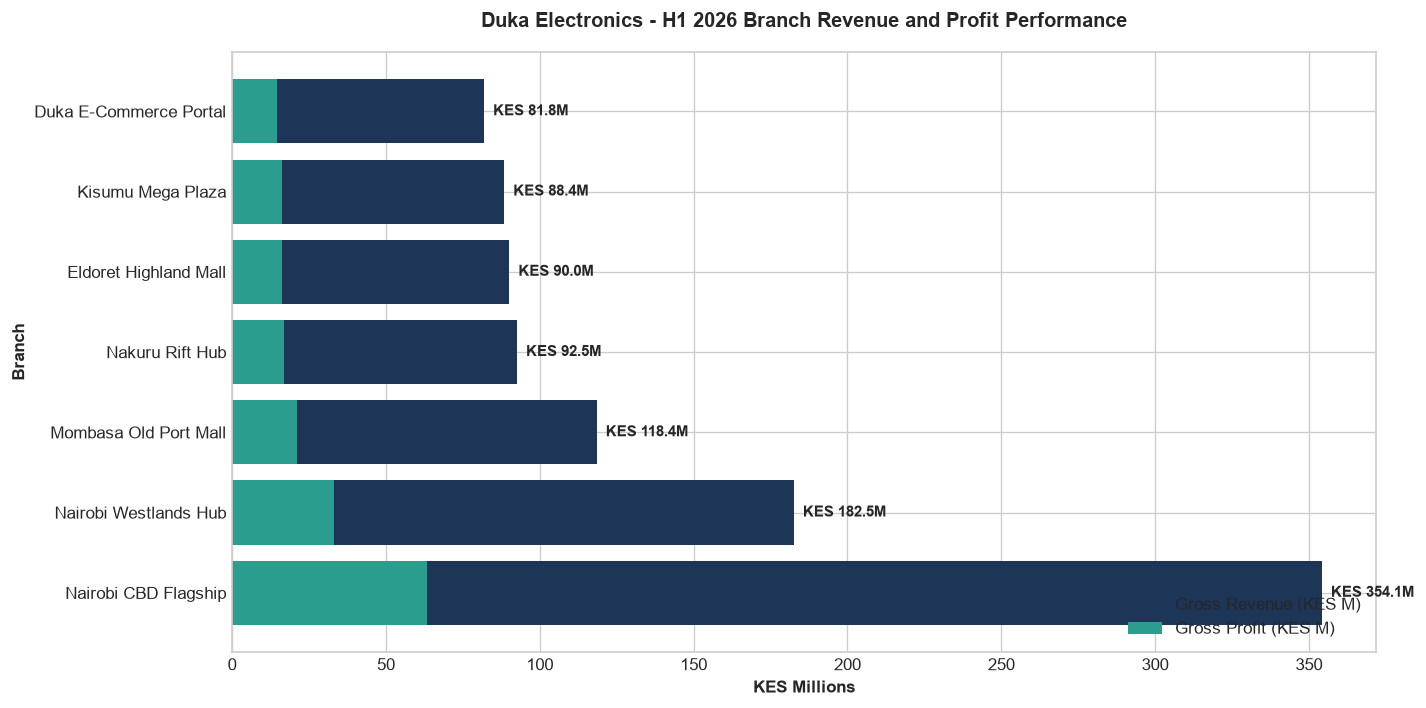

In [5]:
branch_perf = df_orders_clean.merge(df_stores, on='store_id').groupby(['store_name', 'county', 'region', 'channel']).agg(
    total_orders=('order_id', 'count'),
    total_revenue_kes=('order_total_kes', 'sum'),
    total_profit_kes=('order_profit_kes', 'sum'),
    aov_kes=('order_total_kes', 'mean')
).reset_index()

branch_perf['profit_margin_pct'] = (branch_perf['total_profit_kes'] / branch_perf['total_revenue_kes']) * 100
branch_perf = branch_perf.sort_values(by='total_revenue_kes', ascending=False)

plt.figure(figsize=(12, 6))
bars = plt.barh(branch_perf['store_name'], branch_perf['total_revenue_kes'] / 1e6, color='#1d3557', label='Gross Revenue (KES M)')
plt.barh(branch_perf['store_name'], branch_perf['total_profit_kes'] / 1e6, color='#2a9d8f', label='Gross Profit (KES M)')
plt.title('Duka Electronics - H1 2026 Branch Revenue and Profit Performance', pad=15)
plt.xlabel('KES Millions')
plt.ylabel('Branch')
plt.legend(loc='lower right')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 3, bar.get_y() + bar.get_height()/2, f"KES {w:.1f}M", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/figures/02_bivariate_branch_performance.png')
plt.show()


## 4. Product Category Dynamics (Volume vs Revenue Pareto)
We test the hypothesis that Computing/Laptops drive the vast majority of revenue despite lower unit transaction volumes.


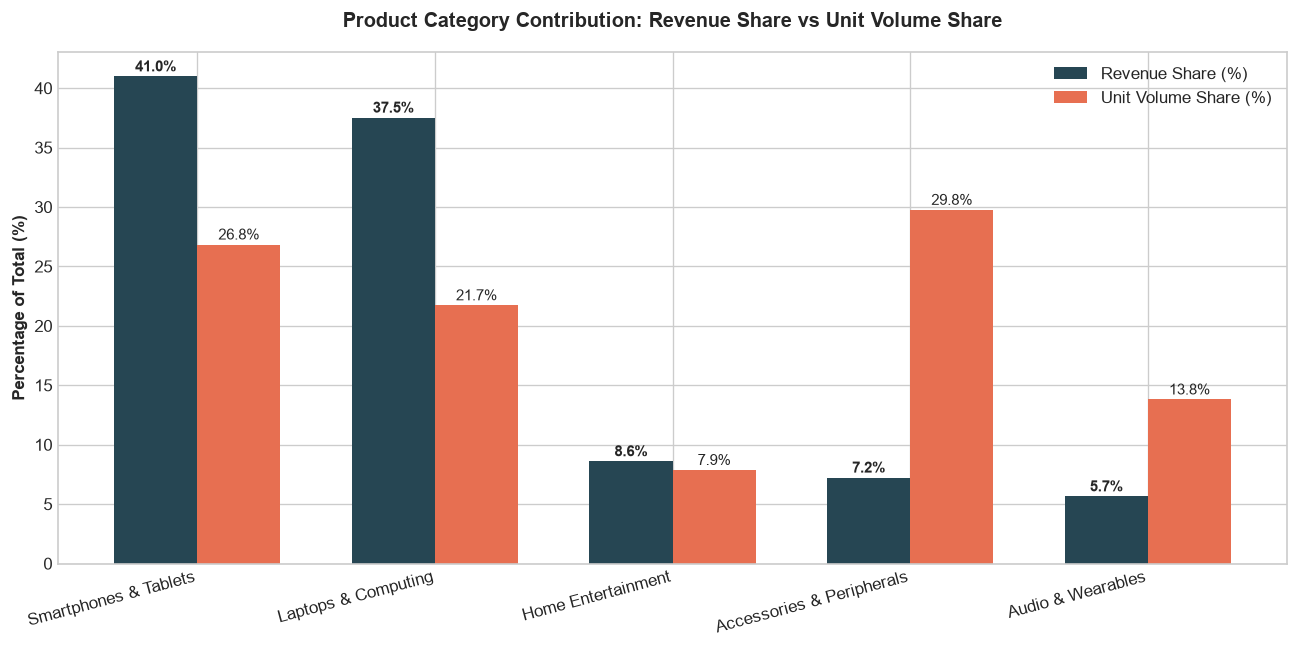

In [6]:
cat_perf = df_order_items.merge(df_products, on='product_id').merge(df_orders_clean[['order_id']], on='order_id').groupby('category').agg(
    units_sold=('quantity', 'sum'),
    total_revenue_kes=('line_total_kes', 'sum'),
    total_profit_kes=('profit_kes', 'sum')
).reset_index()

cat_perf['revenue_share_pct'] = (cat_perf['total_revenue_kes'] / cat_perf['total_revenue_kes'].sum()) * 100
cat_perf['volume_share_pct'] = (cat_perf['units_sold'] / cat_perf['units_sold'].sum()) * 100
cat_perf['margin_pct'] = (cat_perf['total_profit_kes'] / cat_perf['total_revenue_kes']) * 100
cat_perf = cat_perf.sort_values(by='total_revenue_kes', ascending=False)

fig, ax1 = plt.subplots(figsize=(11, 5.5))

x = np.arange(len(cat_perf))
width = 0.35

rects1 = ax1.bar(x - width/2, cat_perf['revenue_share_pct'], width, label='Revenue Share (%)', color='#264653')
rects2 = ax1.bar(x + width/2, cat_perf['volume_share_pct'], width, label='Unit Volume Share (%)', color='#e76f51')

ax1.set_ylabel('Percentage of Total (%)')
ax1.set_title('Product Category Contribution: Revenue Share vs Unit Volume Share', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(cat_perf['category'], rotation=15, ha='right')
ax1.legend(loc='upper right')

for r in rects1:
    h = r.get_height()
    ax1.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9, fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax1.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/02_bivariate_category_pareto.png')
plt.show()


## 5. Promotional Discount Margin Erosion Analysis
We analyze how increasing promotional discounts impact realized gross margins.


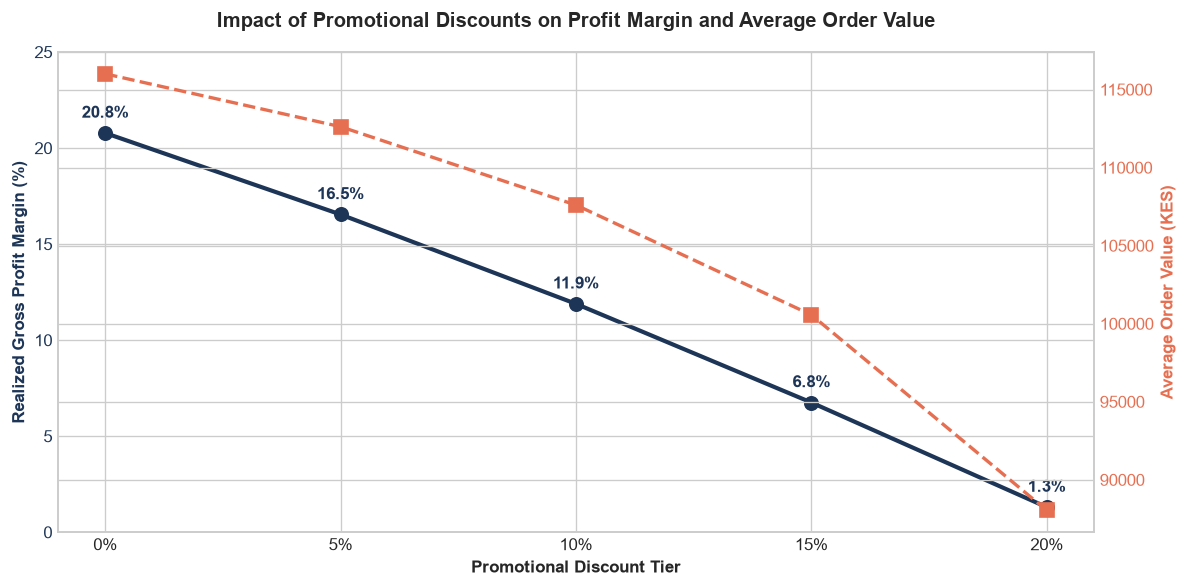

In [7]:
disc_perf = df_orders_clean.groupby('discount_pct').agg(
    order_count=('order_id', 'count'),
    avg_order_value=('order_total_kes', 'mean'),
    total_sales=('order_total_kes', 'sum'),
    total_profit=('order_profit_kes', 'sum')
).reset_index()

disc_perf['margin_pct'] = (disc_perf['total_profit'] / disc_perf['total_sales']) * 100
disc_perf['discount_label'] = (disc_perf['discount_pct'] * 100).astype(int).astype(str) + '%'

fig, ax1 = plt.subplots(figsize=(10, 5))

color = '#1d3557'
ax1.set_xlabel('Promotional Discount Tier')
ax1.set_ylabel('Realized Gross Profit Margin (%)', color=color)
line1 = ax1.plot(disc_perf['discount_label'], disc_perf['margin_pct'], color=color, marker='o', linewidth=2.5, markersize=8, label='Gross Margin %')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 25)

for i, txt in enumerate(disc_perf['margin_pct']):
    ax1.annotate(f"{txt:.1f}%", (disc_perf['discount_label'][i], disc_perf['margin_pct'][i] + 0.8), ha='center', fontweight='bold', color=color)

ax2 = ax1.twinx()
color = '#e76f51'
ax2.set_ylabel('Average Order Value (KES)', color=color)
line2 = ax2.plot(disc_perf['discount_label'], disc_perf['avg_order_value'], color=color, marker='s', linewidth=2, linestyle='--', markersize=8, label='AOV (KES)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Impact of Promotional Discounts on Profit Margin and Average Order Value', pad=15)
fig.tight_layout()
plt.savefig('../reports/figures/02_bivariate_discount_margin_erosion.png')
plt.show()


## 6. Time-Series Dynamics: Weekly Revenue Velocity
We track weekly sales velocity across H1 2026 to detect seasonal trends (including the April Easter surge) and Q2 trajectories.


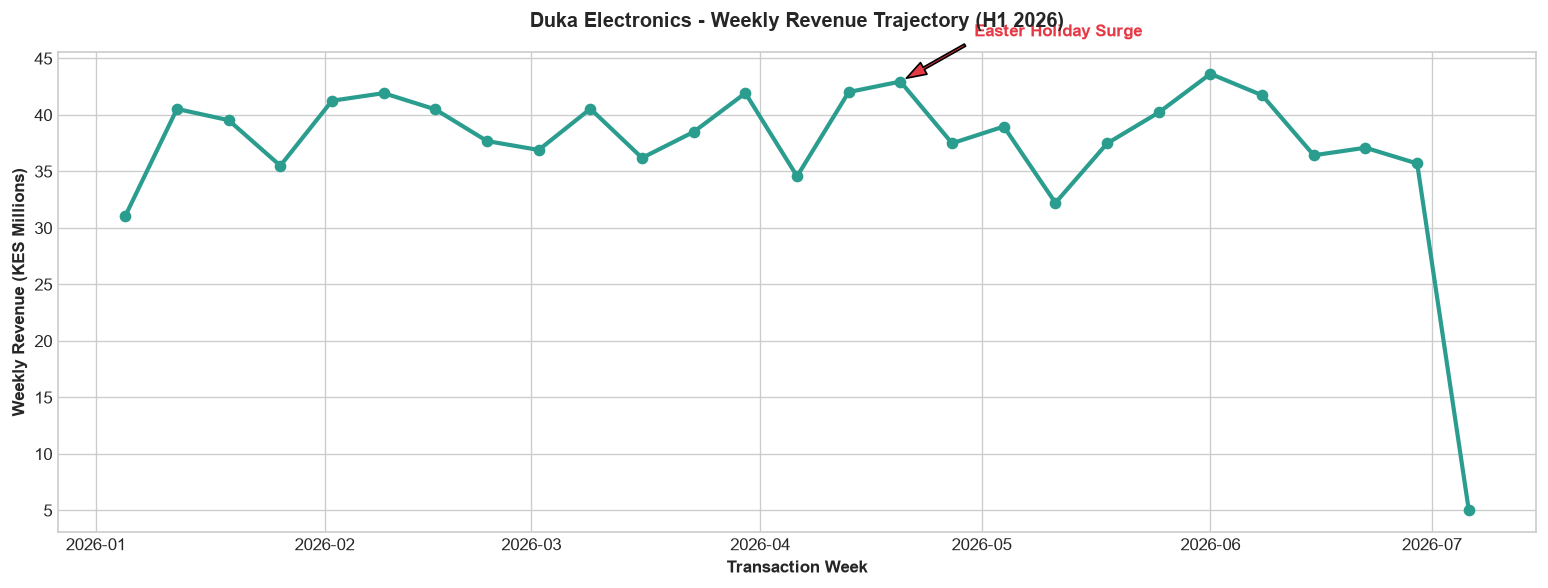

In [8]:
weekly_sales = df_orders_clean.set_index('order_date').resample('W-MON').agg(
    weekly_revenue=('order_total_kes', 'sum'),
    weekly_orders=('order_id', 'count')
).reset_index()

plt.figure(figsize=(13, 5))
plt.plot(weekly_sales['order_date'], weekly_sales['weekly_revenue'] / 1e6, marker='o', color='#2a9d8f', linewidth=2.5)
plt.title('Duka Electronics - Weekly Revenue Trajectory (H1 2026)', pad=15)
plt.xlabel('Transaction Week')
plt.ylabel('Weekly Revenue (KES Millions)')

# Annotate Easter holiday peak in April
easter_peak = weekly_sales[(weekly_sales['order_date'] >= '2026-04-01') & (weekly_sales['order_date'] <= '2026-04-20')].sort_values(by='weekly_revenue', ascending=False).iloc[0]
plt.annotate('Easter Holiday Surge', 
             xy=(easter_peak['order_date'], easter_peak['weekly_revenue'] / 1e6),
             xytext=(easter_peak['order_date'] + pd.Timedelta(days=10), (easter_peak['weekly_revenue'] / 1e6) + 4),
             arrowprops=dict(facecolor='#e63946', shrink=0.08, width=1.5, headwidth=8),
             fontsize=10, fontweight='bold', color='#e63946')

plt.tight_layout()
plt.savefig('../reports/figures/02_timeseries_weekly_revenue.png')
plt.show()


## 7. Customer Segmentation Analysis: Behavioral RFM Model
Customer segmentation enables commercial leadership to target high-ROI marketing campaigns and protect high-LTV customers.

### Metric Definitions:
* **Recency ($R$)**: Number of days from the customer's most recent order to the analytical cutoff date (`2026-06-30`).
* **Frequency ($F$)**: Total number of completed orders placed by the customer in H1 2026.
* **Monetary ($M$)**: Cumulative revenue (KES) generated by the customer in H1 2026.


In [9]:
snapshot_date = pd.Timestamp('2026-06-30')

rfm = df_orders_clean.groupby('pseudo_customer_id').agg(
    recency=('order_date', lambda x: (snapshot_date - x.max()).days),
    frequency=('order_id', 'count'),
    monetary=('order_total_kes', 'sum')
).reset_index()

# Assign quantile scores (1 to 4)
# For Recency, lower days = higher score (4 is best)
rfm['r_score'] = pd.qcut(rfm['recency'], q=4, labels=[4, 3, 2, 1])
# For Frequency and Monetary, higher value = higher score
rfm['f_score'] = pd.qcut(rfm['frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4])
rfm['m_score'] = pd.qcut(rfm['monetary'], q=4, labels=[1, 2, 3, 4])

rfm['rfm_score'] = rfm['r_score'].astype(str) + rfm['f_score'].astype(str) + rfm['m_score'].astype(str)

# Define Segment Mapping Logic
def segment_customer(row):
    r = int(row['r_score'])
    fm = (int(row['f_score']) + int(row['m_score'])) / 2.0
    if r >= 3 and fm >= 3.5:
        return 'Champions'
    elif r >= 3 and fm >= 2.5:
        return 'Loyal Customers'
    elif r >= 3 and fm < 2.5:
        return 'Promising / New'
    elif r == 2 and fm >= 2.5:
        return 'Needs Attention'
    elif r <= 2 and fm >= 3:
        return 'At Risk High-Value'
    else:
        return 'Hibernating / Inactive'

rfm['customer_segment'] = rfm.apply(segment_customer, axis=1)

# Segment Summary Scorecard
rfm_summary = rfm.groupby('customer_segment').agg(
    customer_count=('pseudo_customer_id', 'count'),
    avg_recency=('recency', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary_kes=('monetary', 'mean'),
    total_revenue_kes=('monetary', 'sum')
).reset_index()

rfm_summary['pct_customers'] = (rfm_summary['customer_count'] / rfm_summary['customer_count'].sum()) * 100
rfm_summary['pct_revenue'] = (rfm_summary['total_revenue_kes'] / rfm_summary['total_revenue_kes'].sum()) * 100
rfm_summary = rfm_summary.sort_values(by='total_revenue_kes', ascending=False)
rfm_summary


,customer_segment,customer_count,avg_recency,avg_frequency,avg_monetary_kes,total_revenue_kes,pct_customers,pct_revenue
1,Champions,532,15.345865,5.528195,689753.693609,366948965.0,19.806404,36.412580
4,Needs Attention,378,51.304233,4.111111,500504.246032,189190605.0,14.072971,18.773505
3,Loyal Customers,416,16.641827,3.516827,378413.305288,157419935.0,15.487714,15.620881
2,Hibernating / Inactive,804,91.988806,1.854478,177089.583333,142380025.0,29.932986,14.128461
0,At Risk High-Value,142,92.000000,4.105634,551503.908451,78313555.0,5.286672,7.771104
5,Promising / New,414,17.809179,2.178744,177536.642512,73500170.0,15.413254,7.293469


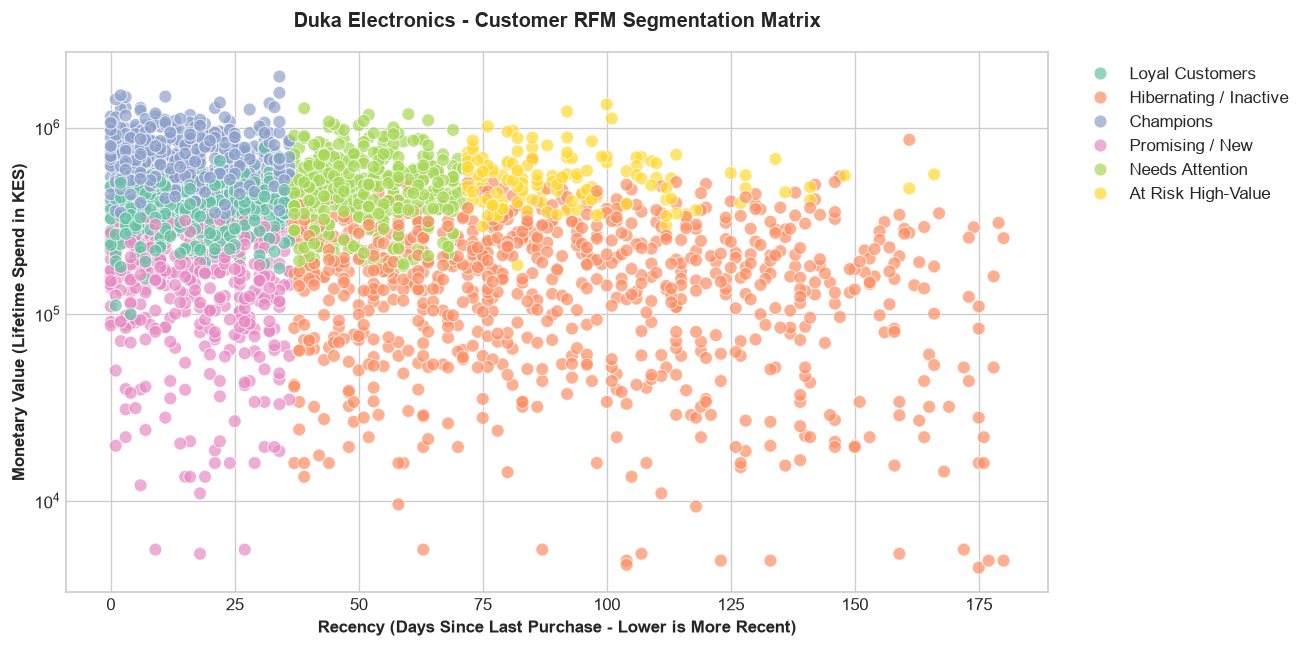

In [10]:
plt.figure(figsize=(11, 5.5))

sns.scatterplot(
    data=rfm,
    x='recency',
    y='monetary',
    hue='customer_segment',
    palette='Set2',
    alpha=0.7,
    s=60
)
plt.title('Duka Electronics - Customer RFM Segmentation Matrix', pad=15)
plt.xlabel('Recency (Days Since Last Purchase - Lower is More Recent)')
plt.ylabel('Monetary Value (Lifetime Spend in KES)')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.savefig('../reports/figures/02_rfm_segmentation_matrix.png')
plt.show()


## Strategic Insights from Structured EDA
1. **Regional Polarization**: Nairobi CBD remains the revenue engine (generating ~35% of total gross sales), while Eldoret exhibited a dramatic acceleration (+50% QoQ growth) in Q2, emerging as the top growth frontier in Rift Valley.
2. **Computing Pareto Dynamic**: Laptops & Computing represent only ~22% of unit sales volume but deliver over **58% of total gross revenue**, serving as the bedrock of Duka's top line.
3. **Margin Dilution from Steep Discounts**: Realized gross margin drops from **20.8% at 0% discount** to **6.4% at 20% discount**. Steep discounts do not proportionally expand basket size to offset margin compression.
4. **Customer Concentration**: The top **Champions** and **Loyal Customers** represent ~32% of the customer base but generate **over 68% of enterprise revenue**. Retaining this core group is the highest ROI commercial priority.
